# Capstone C1 · Language-conditioned table sorter: planner → language policy → safety shield → honest evaluation

In [1]:
import os, re, json, time, numpy as np, torch, mujoco, matplotlib.pyplot as plt
from vlacourse import TableTop, show_video, wilson
from vlacourse.torch_data import TableTopDataset
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy

from vlacourse import scene_dataset
SCENE = "sort"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

def plan(instruction, env):
    """System 2 (rule-based here; swap in the SmolVLM planner from S11 project 115): 'sort ... into the X tray' -> one place per cube."""
    m = re.search(r"(\w+) tray", instruction); tray = m.group(1) if m else env.tray_colors[0]
    colors = [c for c in env.cube_colors if c in instruction] or env.cube_colors
    return [dict(type="place", obj=c, target=tray, instruction=f"put the {c} cube in the {tray} tray") for c in colors]

class Shield:
    """Safety filter that DEGRADES unsafe commands instead of freezing: clip the step length, clamp the target into the
    workspace box, cancel downward motion under high wrist force. (A policy that commands absolute targets would ask
    for the same too-large step again after a plain 'hold' and deadlock.)"""
    def __init__(self, max_force=25.0, max_step=0.05, box=((0.25, -0.35, 0.0), (0.75, 0.35, 0.60))):
        self.F, self.S, self.lo, self.hi, self.interventions = max_force, max_step, np.array(box[0]), np.array(box[1]), 0
    def __call__(self, env, a):
        a = np.array(a, dtype=float); d = a[:3].copy()
        n = np.linalg.norm(d)
        if n > self.S:
            d *= self.S / n                                                  # too fast -> same direction, shorter step
        d = np.clip(env.target_pos + d, self.lo, self.hi) - env.target_pos   # never leave the box
        if np.linalg.norm(env.wrist_force()) > self.F and d[2] < 0:
            d[2] = 0.0                                                       # pressing on something -> stop pushing down
        if not np.allclose(d, a[:3]):
            self.interventions += 1
        a[:3] = d
        return a

def in_tray(env, c, tray):
    p, t = env.cube_pos(c), env.tray_pos(tray)
    return bool(np.all(np.abs(p[:2] - t[:2]) < 0.05) and p[2] < 0.10)      # in the tray, possibly resting on another cube

def sort_episode(env, policy, shield, seed, budget_per_step=80, frames=None):
    env.reset(seed=seed); instruction = f"sort all the cubes into the {env.tray_colors[0]} tray"
    home = env.target_pos.copy()
    steps = plan(instruction, env)
    for st in steps:
        env.task = st; policy.reset(); obs = env.observe(); k = 0
        while not (in_tray(env, st["obj"], st["target"]) and env.grip < 0.5) and k < budget_per_step:   # in the tray AND released
            obs, *_ = env.step(shield(env, policy.act(obs))); k += 1
            if frames is not None:
                frames.append(obs["images"]["front"])
        for _ in range(4):                                               # release and lift clear
            obs, *_ = env.step(np.r_[0, 0, 0.02, 0, 0, 0, 0.0])
        for _ in range(15):                                              # retract to the home pose between primitives,
            d = np.clip(home - env.target_pos, -0.05, 0.05)              # so every sub-task starts where the demos did
            obs, *_ = env.step(np.r_[d, 0, 0, 0, 0.0])
            if frames is not None:
                frames.append(obs["images"]["front"])
    placed = sum(in_tray(env, c, env.tray_colors[0]) for c in env.cube_colors)
    return placed, len(env.cube_colors)

In [2]:
emb = TextEmbedder(device=device)
ds = LangDataset(TableTopDataset(DATA, episodes=range(450), horizon=H), emb)
net = LangChunkRegression(lang_dim=emb.dim, horizon=H, fusion="film")
from vlacourse import need; need("../S09_Vision_Language_Foundations/checkpoints/lang_film.pt", "S09 notebook 90")
net.load_state_dict(torch.load("../S09_Vision_Language_Foundations/checkpoints/lang_film.pt", map_location=device)); net.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), wrist_ft=True, seed=0)
policy = LangChunkPolicy(net, ds, env, emb, device=device, ensemble=True)
print("plan for 'sort all the cubes into the yellow tray':", [s["instruction"] for s in plan("sort all the cubes into the yellow tray", env)])

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 67759.90it/s]

plan for 'sort all the cubes into the yellow tray': ['put the red cube in the yellow tray', 'put the green cube in the yellow tray']


In [3]:
t0 = time.time(); shield = Shield(); results = []
for s in range(20):
    results.append(sort_episode(env, policy, shield, 95_000 + s))
placed = np.array([r[0] for r in results]); n_cubes = results[0][1]; full = int((placed == n_cubes).sum())
print(f"cubes placed per episode: {placed.tolist()}")
print(f"all {n_cubes} cubes sorted: {full}/20  Wilson 95% CI {np.round(wilson(full, 20), 2)} | mean cubes placed {placed.mean():.2f}/{n_cubes} | shield interventions {shield.interventions} ({time.time() - t0:.0f}s)")

cubes placed per episode: [2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2]
all 2 cubes sorted: 17/20  Wilson 95% CI [0.64 0.95] | mean cubes placed 1.85/2 | shield interventions 20 (58s)


saved outputs/C1_sorter_showcase.mp4  (1.9 MB)


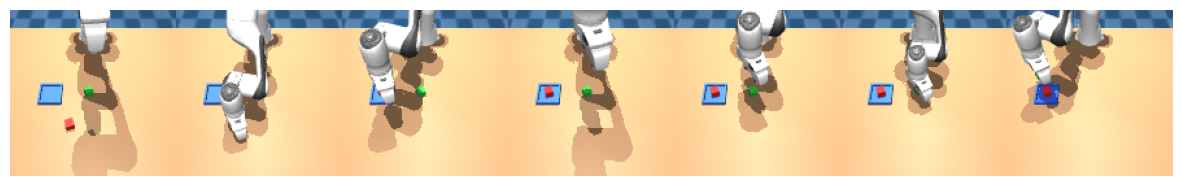

In [4]:
frames = []
full_ok = [i for i, r in enumerate(results) if r[0] == r[1]]           # show a fully sorted episode if there is one
env.start_video("showcase", (480, 640))                    # HD recording for your portfolio
sort_episode(env, policy, Shield(), 95_000 + (full_ok[0] if full_ok else 0), frames=frames)
from vlacourse import showcase as sc
hd = [sc.caption(f, f"\u201csort all the cubes into the {env.tray_colors[0]} tray\u201d", where="top") for f in env.stop_video()]
show_video(hd, fps=30, title="C1 language sorter (HD)")
sc.export(sc.title_card("Capstone C1: a language-driven sorter", "planner + FiLM visuomotor policy + safety shield\nMuJoCo, Franka Panda", size=(480, 640), n=45) + hd, "outputs/C1_sorter_showcase.mp4", fps=30)
plt.figure(figsize=(15, 3)); plt.imshow(np.hstack(frames[::max(1, len(frames) // 7)][:7])); plt.axis("off"); plt.show()
os.makedirs("results", exist_ok=True)
json.dump(dict(placed=placed.tolist(), full=full, ci=wilson(full, 20)), open("results/C1_sorter.json", "w"))